In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import zipfile, os

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.patches as mpatches

username = ''
zip_path = rf'C:\Users\{username}\Downloads\a1-datasets.zip'
extract = rf'C:\Users\{username}\Downloads\a1-datasets'
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract)
os.chdir(extract)

Nulls introduced by merge:
Litter                    1595
Hectare Conditions         163
Other Animal Sightings     111
dtype: int64
Data integration successful. Total records: 2860
Interaction
Indifferent    0.724825
Runs from      0.215734
Approaches     0.059441
Name: proportion, dtype: float64


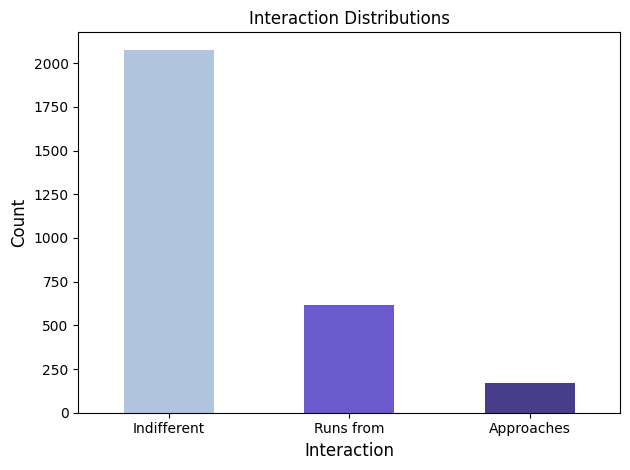

In [11]:
# PRE PROCESSING

# Load data
df_sq = pd.read_csv('squirrel.csv')
df_hec = pd.read_csv('hectare.csv')

# Merge datasets based on Hectare and Shift
df = pd.merge(df_sq, df_hec[['Hectare', 'Shift', 'Litter', 'Hectare Conditions', 'Other Animal Sightings']], 
              on=['Hectare', 'Shift'], how='left')

# Print a report of all the missing values obtained when the data is merged
print(f"Nulls introduced by merge:\n{df[['Litter','Hectare Conditions','Other Animal Sightings']].isnull().sum()}")

# after having seen the missing values we chose to remove the 
# litter condition and the rows with missing hectare condtions
df = df.drop(columns=['Litter'])
df = df.dropna(subset=['Hectare Conditions'])

# Assign numerical values to the categorical interaction observations
def get_label(r):
    if str(r['Approaches']).lower() == 'true': return 1 
    if str(r['Runs from']).lower() == 'true': return 2 
    return 0 
df['Interaction'] = df.apply(get_label, axis=1)

# Feature encoding and quantization
df['Busy_Stress'] = df['Hectare Conditions'].map({'Busy': 2, 'Calm, Busy': 2, 'Moderate': 1, 'Medium': 1, 'Calm': 0})
df['Dog_Nearby'] = df['Other Animal Sightings'].str.contains('Dogs', na=False, case=False).astype(int)

# map binary values to the True or false bools in the behaviour categories
for actions in ['Running', 'Chasing', 'Climbing', 'Eating', 'Foraging']:
    df[actions] = df[actions].map({True: 1, False: 0}).fillna(0)

# Print report (df.head()) was used to make sure data table was correct
print(f"Data integration successful. Total records: {len(df)}")
df.head()

# Finding the proportions of each interaction within the set
print(df['Interaction'].map({0:'Indifferent', 1:'Approaches', 2:'Runs from'}).value_counts(normalize=True))
# Creates a graph of the proportions from line above
plt.figure()
df['Interaction'].map({0:'Indifferent', 1:'Approaches', 2:'Runs from'}).value_counts().plot(kind='bar', color=['lightsteelblue', 'slateblue', 'darkslateblue'])
plt.title('Interaction Distributions')
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=0)
plt.xlabel('Interaction', fontsize=12)
plt.tight_layout()
plt.show()

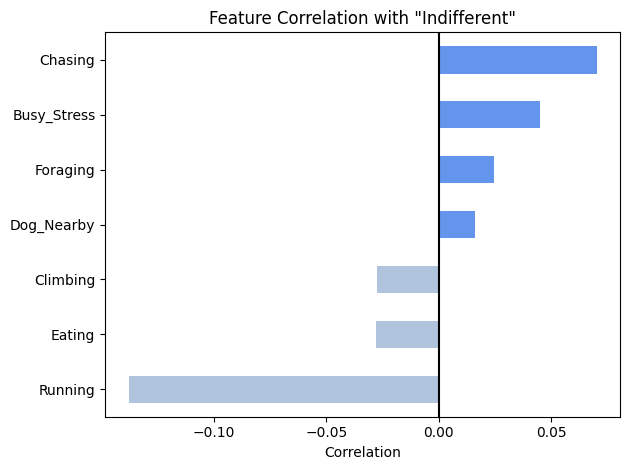

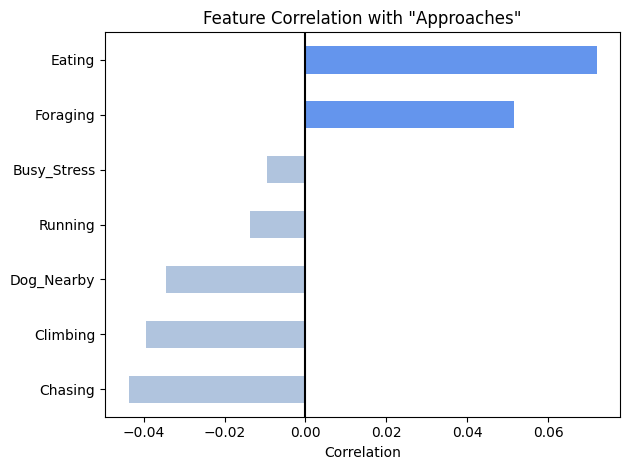

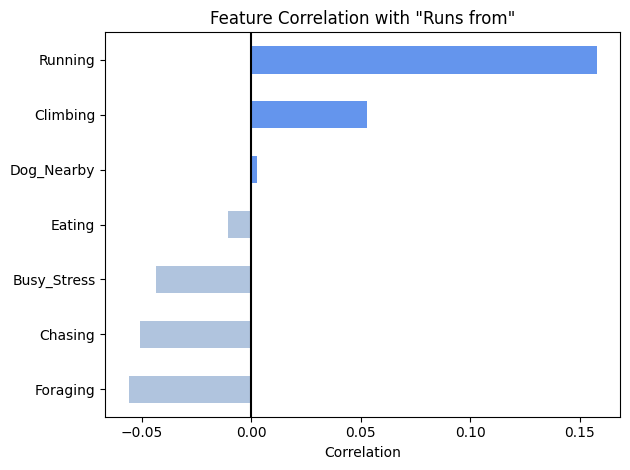

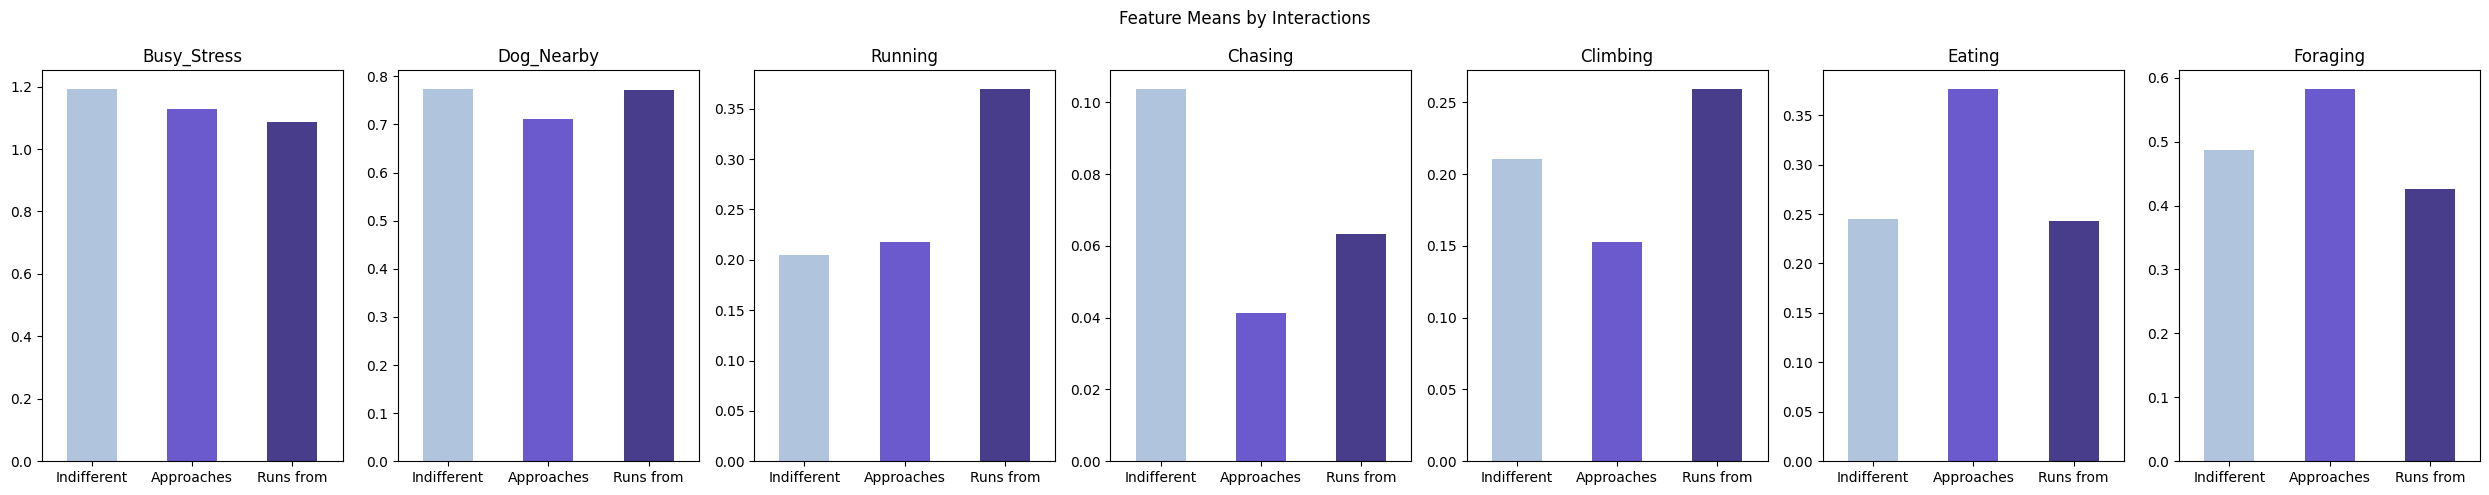

In [12]:
# CORRELATION

# Defines the 7 features used across the models and clustering
features = ['Busy_Stress', 'Dog_Nearby', 'Running', 'Chasing', 'Climbing', 'Eating', 'Foraging']
# Dictioary to convert the numeric values to names for display in charts
label_map = {0: 'Indifferent', 1: 'Approaches', 2: 'Runs from'}

# Loop through each interaction to make seperate bar charts
for label, name in label_map.items():
    binary = (df['Interaction'] == label).astype(int)
    # Calculate the correlations between the features and binary class indicator
    correlations = df[features].corrwith(binary).sort_values()
    plt.figure()
    correlations.plot(kind='barh', color=['lightsteelblue' if x < 0 else 'cornflowerblue' for x in correlations])
    plt.title(f'Feature Correlation with "{name}"')
    plt.xlabel('Correlation')
    plt.axvline(0, color='black')
    plt.tight_layout()
    plt.show()

# Creates a figure with 7 subplots (one per feature)
fig, axes = plt.subplots(1, 7, figsize=(25, 5))
# Loop through each feature 
for ax, feature in zip(axes.flat, features):
    # calculate mean value of the feature for the specific interaction
    df.groupby('Interaction')[feature].mean().rename(label_map).plot(
        kind='bar', ax=ax, color=['lightsteelblue', 'slateblue', 'darkslateblue'])
    ax.set_title(feature)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    
plt.suptitle('Feature Means by Interactions')
plt.tight_layout()
plt.show()


──────────────────────────────────────────────────
Random Forest
──────────────────────────────────────────────────
              precision    recall  f1-score   support

 Indifferent       0.75      0.41      0.53       415
  Approaches       0.09      0.56      0.15        34
   Runs from       0.28      0.29      0.29       123

    accuracy                           0.40       572
   macro avg       0.37      0.42      0.32       572
weighted avg       0.61      0.40      0.46       572


──────────────────────────────────────────────────
Decision Tree
──────────────────────────────────────────────────
              precision    recall  f1-score   support

 Indifferent       0.76      0.36      0.49       415
  Approaches       0.09      0.59      0.15        34
   Runs from       0.27      0.31      0.29       123

    accuracy                           0.37       572
   macro avg       0.37      0.42      0.31       572
weighted avg       0.61      0.37      0.43       572


───

c:\Users\jordy\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jordy\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jordy\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

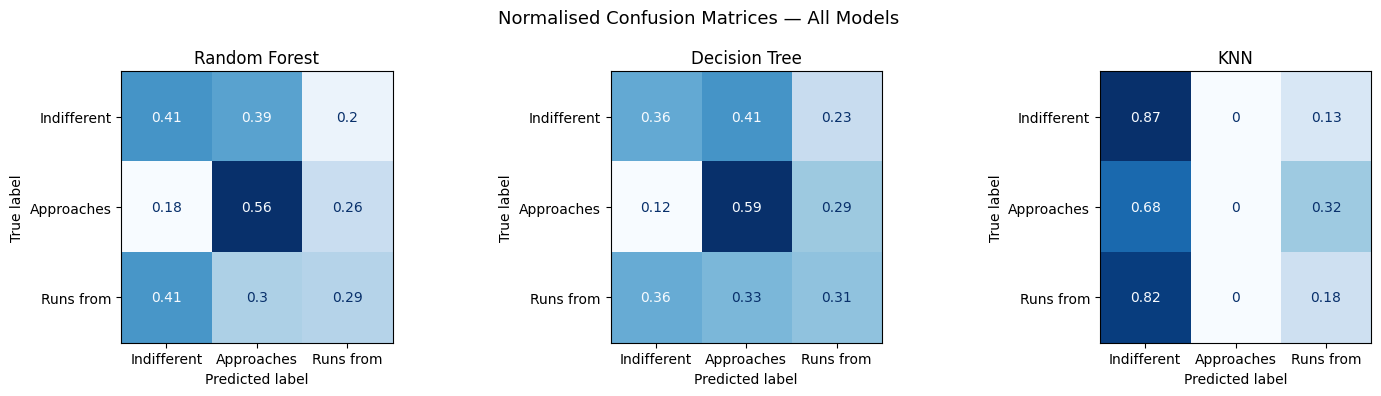

Random Forest Accuracy: 0.3951
Decision Tree Accuracy: 0.3654
KNN Accuracy: 0.6678


C:\Users\jordy\AppData\Local\Temp\ipykernel_11888\3703138600.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy', data=comparison_df, palette='viridis')


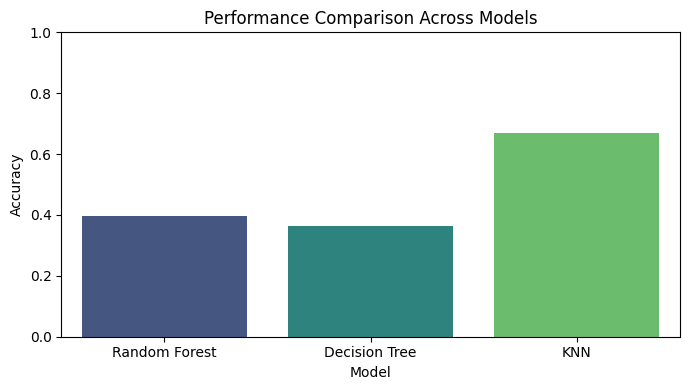

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

 Indifferent       0.75      0.41      0.53       415
  Approaches       0.09      0.56      0.15        34
   Runs from       0.28      0.29      0.29       123

    accuracy                           0.40       572
   macro avg       0.37      0.42      0.32       572
weighted avg       0.61      0.40      0.46       572



C:\Users\jordy\AppData\Local\Temp\ipykernel_11888\3703138600.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance, y=importance.index, palette='Blues')


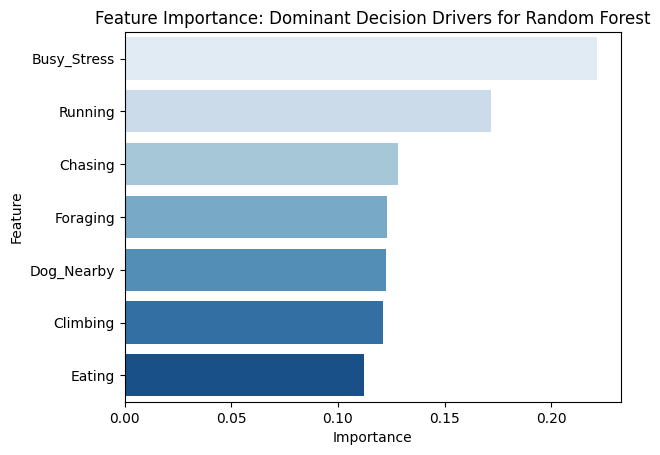

--- Decision Tree Classification Report ---
              precision    recall  f1-score   support

 Indifferent       0.76      0.36      0.49       415
  Approaches       0.09      0.59      0.15        34
   Runs from       0.27      0.31      0.29       123

    accuracy                           0.37       572
   macro avg       0.37      0.42      0.31       572
weighted avg       0.61      0.37      0.43       572



C:\Users\jordy\AppData\Local\Temp\ipykernel_11888\3703138600.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance, y=importance.index, palette='Blues')


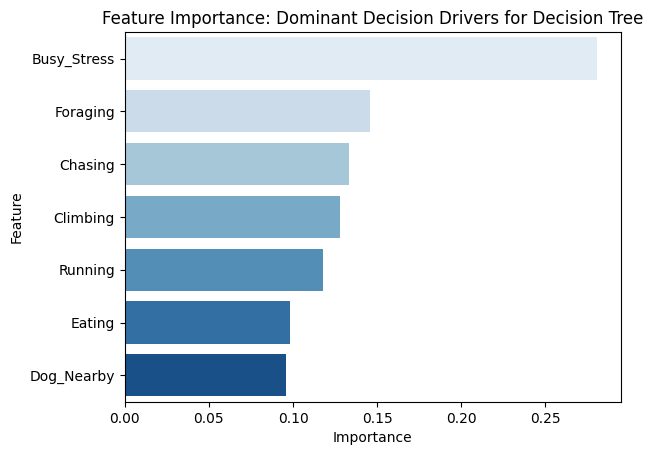

In [13]:
# SUPERVISED LEARNING MODELS 

# assign features to X and interactions to Y to seperate them
X = df[features]
y = df['Interaction']

# Split it into 80% training and 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define the 3 models, use class_weight='balanced' to adjust for imbalance
models = {"Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'), "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight='balanced'), "KNN": Pipeline([('scaler', StandardScaler()),('knn', KNeighborsClassifier(n_neighbors=3))])}
# Train the models
for name, model in models.items():
    model.fit(X_train, y_train)
# print a report for each model showing precision recall and accuracy for results
for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"\n{'─'*50}")
    print(name)
    print('─'*50)
    print(classification_report(y_test, y_pred, target_names=['Indifferent', 'Approaches', 'Runs from']))

# Create the normalised confusion matrices and have them plotted 
# side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    matrix = confusion_matrix(y_test, y_pred, normalize='true')
    disp = ConfusionMatrixDisplay(matrix, display_labels=['Indifferent','Approaches','Runs from']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.suptitle('Normalised Confusion Matrices — All Models', fontsize=13)
plt.tight_layout()
plt.show()
# calculates the accuracy for each model and plots a bar chart for the vals
results = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

comparison_df = pd.DataFrame(results.items(), columns=['Model', 'Accuracy'])
plt.figure(figsize=(7, 4))
sns.barplot(x='Model', y='Accuracy', data=comparison_df, palette='viridis')
plt.title('Performance Comparison Across Models')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

randforest_model = models["Random Forest"]
y_pred_rf = randforest_model.predict(X_test)

print("--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf, target_names=['Indifferent', 'Approaches', 'Runs from']))

# Feature Importance for random forest
importance = pd.Series(randforest_model.feature_importances_, index=features).sort_values(ascending=False)
sns.barplot(x=importance, y=importance.index, palette='Blues')
plt.title('Feature Importance: Dominant Decision Drivers for Random Forest')
plt.ylabel('Feature')
plt.xlabel('Importance')
plt.show()

dec_tree_model = models["Decision Tree"]
y_pred_dt = dec_tree_model.predict(X_test)

print("--- Decision Tree Classification Report ---")
print(classification_report(y_test, y_pred_dt, target_names=['Indifferent', 'Approaches', 'Runs from']))

# Feature Importance for decision tree
importance = pd.Series(dec_tree_model.feature_importances_, index=features).sort_values(ascending=False)
sns.barplot(x=importance, y=importance.index, palette='Blues')
plt.title('Feature Importance: Dominant Decision Drivers for Decision Tree')
plt.ylabel('Feature')
plt.xlabel('Importance')
plt.show()

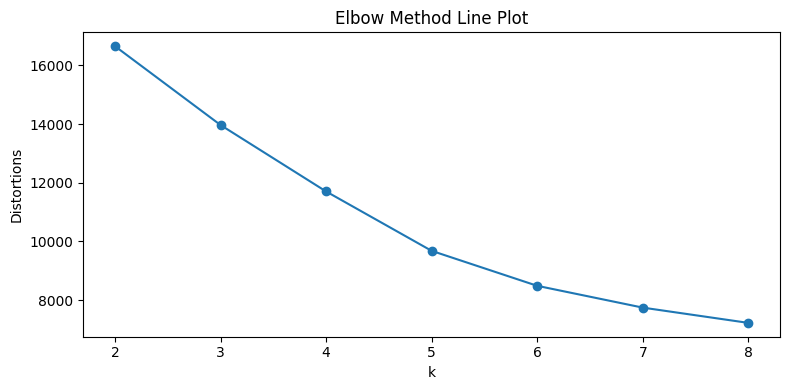


Average Feature Values (Clusters): 
         Busy_Stress  Dog_Nearby  Running  Chasing  Climbing  Eating  Foraging
Cluster                                                                       
0              1.249       0.802    0.081      0.0     0.061   1.000     0.539
1              1.103       0.800    0.188      0.0     1.000   0.110     0.147
2              1.140       0.771    1.000      0.0     0.000   0.078     0.233
3              1.156       0.735    0.000      0.0     0.000   0.000     0.811
4              1.188       0.762    0.291      1.0     0.165   0.115     0.207


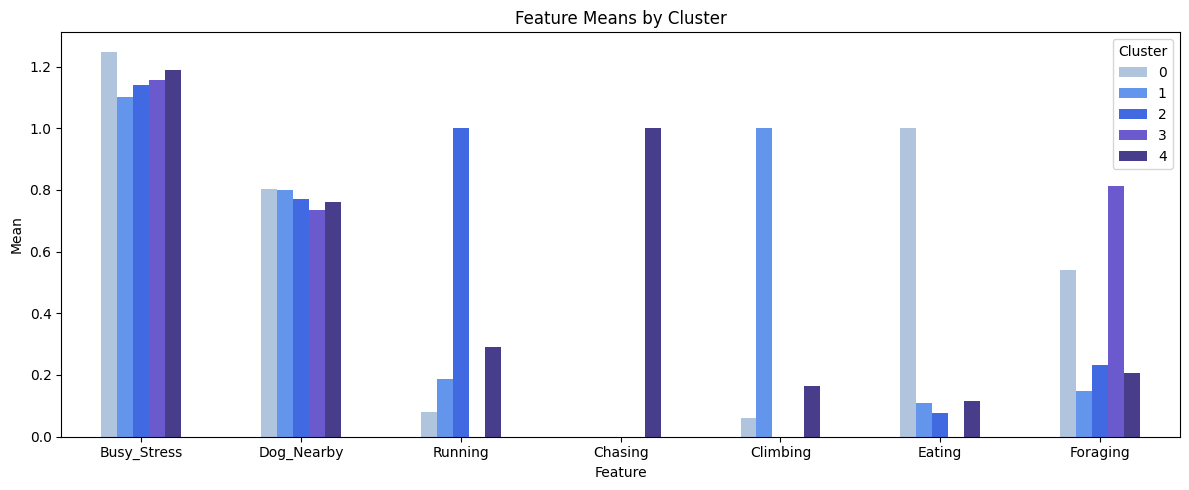

In [14]:
# CLUSTERING

# standardise features before clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# elbow method line chart development
k_range = range(2, 9)
distortions = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    distortions.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, distortions, marker='o')
plt.title('Elbow Method Line Plot')
plt.xlabel('k')
plt.ylabel('Distortions')
plt.tight_layout()
plt.show()

# Make the optimal k=5
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

Cluster_means = df.groupby('Cluster')[features].mean()
print("\nAverage Feature Values (Clusters): ")
print(Cluster_means.round(3))

Cluster_means.T.plot(kind='bar', figsize=(12, 5), color=['lightsteelblue', 'cornflowerblue', 'royalblue', 'slateblue', 'darkslateblue'])
plt.title('Feature Means by Cluster')
plt.xlabel('Feature')
plt.ylabel('Mean')
plt.xticks(rotation=0)
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()